# Fig. S1 — Evolutionary phase lines under growth-coupled logistic regulation
Top: $\dot x/(1-N/K)$ against $x$ with fixed points (filled: stable, open: unstable) and flow direction.
Bottom: $x(t)$ from $N(0)=10^7$, $x(0)=0.5$, $K=10^{10}$; the dashed line marks $N = 0.999K$, after which the composition is frozen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

In [2]:
def g(x, b, gm):
    return x * (1 - x) * ((b - DELTA) * (1 - x) - (gm - ALPHA) * x)

def fixed_points(b, gm):
    fps = [0.0, 1.0]
    xs = interior_equilibrium(ALPHA, b, DELTA * 0 + DELTA, gm) if False else interior_equilibrium(ALPHA, b, gm, DELTA)
    if 0 < xs < 1:
        fps.append(xs)
    return fps

def stable(fp, b, gm, h=1e-6):
    if fp == 0.0: return b < DELTA
    if fp == 1.0: return gm < ALPHA
    return (g(fp + h, b, gm) - g(fp - h, b, gm)) / (2 * h) < 0

x = np.linspace(0, 1, 1000)
traj = {name: simulate(ALPHA, b, gm, DELTA, x0=0.5, n0=1e7, T=60, dt=0.01, return_traj=True, n_save=1200)
        for name, (b, gm) in REGIMES.items()}

Snowdrift            N = 0.999K at day 20.9; x then = 0.370
Harmony              N = 0.999K at day 32.5; x then = 0.958
Coordination         N = 0.999K at day 26.9; x then = 0.020
Prisoner's Dilemma   N = 0.999K at day 23.7; x then = 0.008


Saved ../figures/FigS1_phase_lines_growth_coupled.png/.pdf


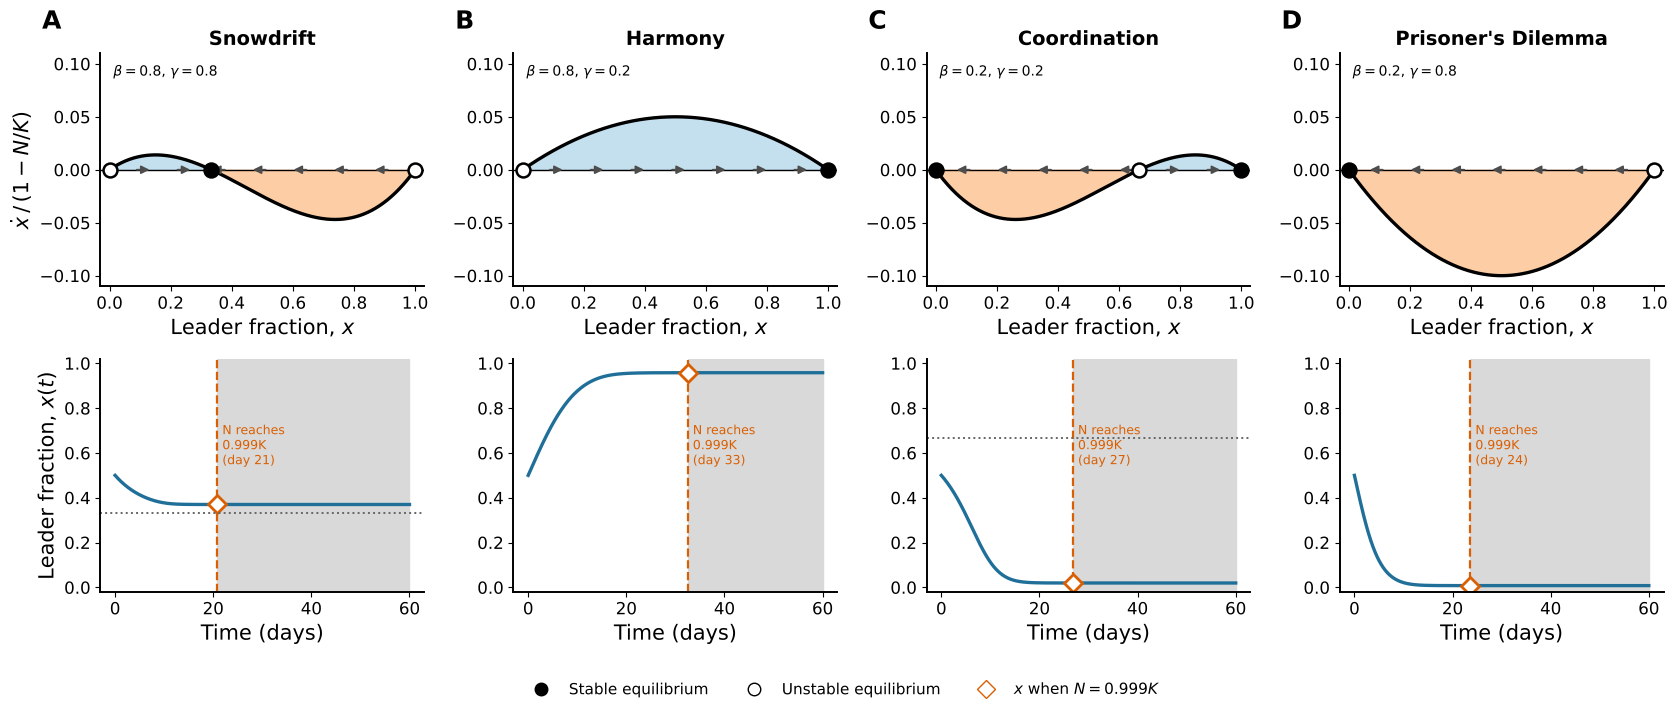

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, (name, (b, gm)) in enumerate(REGIMES.items()):
    ax = axes[0, j]; y = g(x, b, gm)
    ax.fill_between(x, 0, y, where=y > 0, color="#9ecae1", alpha=0.6)
    ax.fill_between(x, 0, y, where=y < 0, color="#fdae6b", alpha=0.6)
    ax.plot(x, y, "k", lw=2.4); ax.axhline(0, color="k", lw=1)
    for xx in np.linspace(0.1, 0.9, 7):
        v = g(xx, b, gm)
        if abs(v) > 1e-4:
            s = np.sign(v)
            ax.annotate("", xy=(xx + 0.04 * s, 0), xytext=(xx - 0.02 * s, 0),
                        arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1.3))
    for fp in fixed_points(b, gm):
        ax.plot(fp, 0, "o", ms=10, mfc="k" if stable(fp, b, gm) else "white", mec="k", mew=1.8, zorder=5)
    ax.set_ylim(-0.11, 0.11); ax.set_xlim(-0.03, 1.03)
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("Leader fraction, $x$")
    ax.text(0.04, 0.95, rf"$\beta={b}$, $\gamma={gm}$", transform=ax.transAxes, va="top", fontsize=10)
    panel_letter(ax, "ABCD"[j])

    ax = axes[1, j]; _, _, t, xs, ns = traj[name]
    t_sat = t[np.argmax(ns >= 0.999 * K)]
    ax.axvspan(t_sat, t[-1], color="0.85")
    ax.plot(t, xs, color="#1f6f99", lw=2.4)
    ax.axvline(t_sat, color="#d95f02", ls="--", lw=1.6)
    ax.plot(t_sat, np.interp(t_sat, t, xs), "D", mfc="white", mec="#d95f02", ms=9, mew=2)
    ax.text(t_sat + 1, 0.55, f"N reaches\n0.999K\n(day {t_sat:.0f})", color="#d95f02", fontsize=9)
    xs_int = interior_equilibrium(ALPHA, b, gm, DELTA)
    if 0 < xs_int < 1:
        ax.axhline(xs_int, color="0.4", ls=":", lw=1.4)
    ax.set_ylim(-0.02, 1.02); ax.set_xlabel("Time (days)")
    print(f"{name:20s} N = 0.999K at day {t_sat:.1f}; x then = {np.interp(t_sat, t, xs):.3f}")
axes[0, 0].set_ylabel(r"$\dot x\,/\,(1-N/K)$"); axes[1, 0].set_ylabel("Leader fraction, $x(t)$")
handles = [plt.Line2D([], [], marker="o", ls="none", mfc="k", mec="k", ms=9, label="Stable equilibrium"),
           plt.Line2D([], [], marker="o", ls="none", mfc="white", mec="k", ms=9, label="Unstable equilibrium"),
           plt.Line2D([], [], marker="D", ls="none", mfc="white", mec="#d95f02", ms=9, label="$x$ when $N = 0.999K$")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=[0, 0.04, 1, 1])
save(fig, "FigS1_phase_lines_growth_coupled")
plt.show()